# **Projet PYPSA**

In [1]:
%pip install pypsa


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\arthu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pypsa
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from pypsa import Network

## **Créer le réseau francais**

In [3]:
import pypsa
import pandas as pd

# ============================================================
# CHARGEMENT DES DONNÉES (une seule fois)
# ============================================================
df_donnees = pd.read_parquet(r"C:\PERSO\pypsa\dataset_consolide.parquet")
df_donnees["datetime"] = pd.to_datetime(df_donnees["datetime"])
df_donnees = df_donnees.set_index("datetime")

cap_solar = df_donnees["SOLAR_capacite_installee"].max() #pv
cap_wind = (df_donnees["WIND_OFFSHORE_capacite_installee"]
            + df_donnees["WIND_ONSHORE_capacite_installee"]).max() #éolien
cap_hrun = df_donnees["HYDRO_RUN_OF_RIVER_AND_POUNDAGE_capacite_installee"].max() #fil de l'eau
cap_waste = df_donnees["WASTE_capacite_installee"].max() #déchets
cap_nuc = df_donnees["NUCLEAR_capacite_installee"].max() #nucléaire
cap_gas = df_donnees["FOSSIL_GAS_capacite_installee"].max() #gas
cap_coal = df_donnees["FOSSIL_HARD_COAL_capacite_installee"].max() #charbon
cap_fioul = df_donnees["FOSSIL_OIL_capacite_installee"].max() #fioul
cap_bio = df_donnees["BIOMASS_capacite_installee"].max() #biomasse
cap_reservoir = df_donnees["HYDRO_WATER_RESERVOIR_capacite_installee"].max() #réservoirs
cap_pump = df_donnees["HYDRO_PUMPED_STORAGE_capacite_installee"].max() #step

#Fonction qui calcule la disponibilité de la source d'énergie à un instant t
def dispo(cap_max, indispo_col):
    disponible_t = cap_max - df_donnees[indispo_col]  # capacité(t) - indispo(t), mesure physique à t
    return disponible_t / cap_max  # dénominateur fixe = p_nom

def dispo_nucleaire(cap_max, indispo_col, facteur_indispo=1.0):
    disponible_t = cap_max - df_donnees[indispo_col] * facteur_indispo
    disponible_t = disponible_t.clip(lower=0)
    return disponible_t / cap_max

# ============================================================
# PARAMÈTRES PAR DÉFAUT — hypothèses sur les valeurs
# ============================================================
PARAMS_DEFAUT = {
    # Coûts marginaux
    "cout_marginal_nucleaire": 10,   # Sensibilité entre 5 et 12
    "prix_charbon_hyp": 15,
    "prix_fioul_hyp": 40,
    "cout_marginal_hydro_fil_eau": 1,  # Coût très faible
    "cout_marginal_barrage": 3,        # Sensibilité 1 à 5
    "cout_marginal_step": 3,           # Sensibilité 1 à 5
    "cout_marginal_biomasse": 20,
    "cout_marginal_waste": 15,
    # Rendement des centrales thermiques
    "rendement_gaz": 0.55,      # Sensibilité entre 0.55 et 0.58 ; mix majoritairement CCGT
    "rendement_charbon": 0.38,  # Sensibilité 0.35 à 0.4
    "rendement_fioul": 0.40,    # Sensibilité 0.35 à 0.4
    # Émissions des vecteurs énergétiques thermiques (tCO2/MWh_th)
    "emission_gaz": 0.202,
    "emission_charbon": 0.35,   # Sensibilité 0.34 à 0.36
    "emission_fioul": 0.275,    # Sensibilité 0.265 à 0.285
}

# ============================================================
# CONSTRUCTION + RÉSOLUTION DU RÉSEAU, PARAMÉTRABLE
# ============================================================
def build_and_solve_network(overrides=None, co2_cap=None, facteur_indispo_nucleaire = 1, ecrire_lp=False, solver_name="highs"):
    """Construit le Network PyPSA avec les paramètres par défaut, en
    écrasant ceux fournis dans `overrides`, puis résout et retourne le
    Network. Permet de relancer facilement pour une étude de sensibilité
    sans dupliquer toute la construction à la main."""
    p = {**PARAMS_DEFAUT, **(overrides or {})}

    # On crée le réeau
    n = pypsa.Network()
    n.set_snapshots(df_donnees.index)

    # On ajoute un unique bus, connecté à tous les générateurs, et à la charge
    n.add("Bus", "reseau")

    # Les deux charges : conso (positif, consomme) et échange
    # (solde_export_mw positif = France exportatrice = comportement de charge ;
    #  négatif = import net = injection nette sur le bus)
    n.add("Load", "conso", bus="reseau", p_set=df_donnees["conso_prevue"])
    n.add("Load", "echange", bus="reseau", p_set=df_donnees["solde_export_mw"])

    # Générateurs NON PILOTABLES : on utilise tel quel ce qui a été produit les années d'études

    # Renouvelables
    n.add("Generator", "solar", bus="reseau", carrier="solar",
          p_nom=cap_solar, p_min_pu=0,
          p_max_pu=df_donnees["prod_SOLAR"].clip(lower=0) / cap_solar, marginal_cost=0) #Cout marginal nul

    n.add("Generator", "wind", bus="reseau", carrier="wind",
          p_nom=cap_wind, p_min_pu=0,
          p_max_pu=df_donnees["prod_WIND"].clip(lower=0) / cap_wind, marginal_cost=0)

    # Hydro fil de l'eau
    n.add("Generator", "hydro_river", bus="reseau", carrier="hydro",
      p_nom=cap_hrun, p_min_pu=0,
      p_max_pu=df_donnees["prod_hydro_river_mw"].clip(lower=0) / cap_hrun,
      marginal_cost=p["cout_marginal_hydro_fil_eau"])

    # Déchets (hyp : non pilotable, on arrête pas les usines d'incinérations pour des raisons économiques)
    n.add("Generator", "waste", bus="reseau", carrier="waste",
          p_nom=cap_waste, p_min_pu=0,
          p_max_pu=df_donnees["prod_waste_mw"].clip(lower=0) / cap_waste,
          marginal_cost=p["cout_marginal_waste"])

    # Généateurs PILOTABLES (le solveur peut optimiser)

    # Nucléaire
    n.add("Generator", "nucleaire", bus="reseau", carrier="nucleaire",
      p_nom=cap_nuc, p_min_pu=0,
      p_max_pu=dispo_nucleaire(cap_nuc, "nuclear_indispo_mw", facteur_indispo_nucleaire),
      marginal_cost=p["cout_marginal_nucleaire"])

    # Thermiques
    n.add("Generator", "gaz", bus="reseau", carrier="gaz",
          p_nom=cap_gas, p_min_pu=0,
          p_max_pu=dispo(cap_gas, "gas_indispo_mw"),
          marginal_cost=df_donnees["TTF"] / p["rendement_gaz"]
                        + df_donnees["EUA"] * p["emission_gaz"] / p["rendement_gaz"])

    n.add("Generator", "charbon", bus="reseau", carrier="charbon",
          p_nom=cap_coal, p_min_pu=0,
          p_max_pu=dispo(cap_coal, "coal_indispo_mw"),
          marginal_cost=p["prix_charbon_hyp"] / p["rendement_charbon"]
                        + df_donnees["EUA"] * p["emission_charbon"] / p["rendement_charbon"])

    n.add("Generator", "fioul", bus="reseau", carrier="fioul",
          p_nom=cap_fioul, p_min_pu=0,
          p_max_pu=dispo(cap_fioul, "oil_indispo_mw"),
          marginal_cost=p["prix_fioul_hyp"] / p["rendement_fioul"]
                        + df_donnees["EUA"] * p["emission_fioul"] / p["rendement_fioul"])

    n.add("Generator", "biomass", bus="reseau", carrier="biomass",
          p_nom=cap_bio, p_min_pu=0,
          p_max_pu=dispo(cap_bio, "biomass_indispo_mw"),
          marginal_cost=p["cout_marginal_biomasse"])
 
    # Sources énergétiques qui peuvent être stockées (réservoir, step)
    # Hydraulique à stock
    n.add("StorageUnit", "hydro_reservoir", bus="reseau", carrier="hydro",
          p_nom=cap_reservoir,
          p_min_pu=0,  # pas de pompage : un réservoir ne se remplit pas depuis le réseau
          p_max_pu=dispo(cap_reservoir, "hydro_reservoir_indispo_mw"),
          max_hours=500,  # HYPOTHÈSE : stockage saisonnier
          inflow=df_donnees["prod_hydro_reservoir_mw"].clip(lower=0),
          efficiency_store=1, efficiency_dispatch=1,  # pas de perte modélisée (HYPOTHÈSE)
          cyclic_state_of_charge=True,  # évite un remplissage/vidage "gratuit" en début/fin de série
          marginal_cost=p["cout_marginal_barrage"])

    n.add("StorageUnit", "hydro_pump", bus="reseau", carrier="hydro",
          p_nom=cap_pump,
          p_min_pu=-dispo(cap_pump, "hydro_pump_indispo_mw"),  # peut pomper jusqu'à sa dispo
          p_max_pu=dispo(cap_pump, "hydro_pump_indispo_mw"),   # peut turbiner jusqu'à sa dispo
          max_hours=6,  # HYPOTHÈSE : cycle journalier typique STEP
          inflow=0,
          efficiency_store=0.9, efficiency_dispatch=0.9,  # 0,81 rendement aller-retour
          cyclic_state_of_charge=True,
          marginal_cost=p["cout_marginal_step"])

    # Ajout d'un générateur avec un cout énorme qui fait office de grid (si production + import < demande); permettant au solveur d'aboutir
    n.add("Generator", "delestage", bus="reseau", carrier="delestage",
      p_nom=1e6,          # capacité quasi illimitée : ne doit jamais contraindre, seulement débloquer
      p_min_pu=0, p_max_pu=1,
      marginal_cost=3000) # prix très supérieur à toute filière réelle : n'est appelé qu'en dernier recours

    # Contrainte CO2
    if co2_cap is not None:
        n.add("Carrier", "gaz", co2_emissions=p["emission_gaz"])
        n.add("Carrier", "charbon", co2_emissions=p["emission_charbon"])
        n.add("Carrier", "fioul", co2_emissions=p["emission_fioul"])
        n.generators.loc["gaz", "efficiency"] = p["rendement_gaz"]
        n.generators.loc["charbon", "efficiency"] = p["rendement_charbon"]
        n.generators.loc["fioul", "efficiency"] = p["rendement_fioul"]

        #La contrainte sur le CO2
        n.add("GlobalConstraint", "co2_limit", type="co2_emissions",
              carrier_attribute="co2_emissions", sense="<=", constant=co2_cap)

    n.optimize.create_model()
    if ecrire_lp:
        n.model.to_file("modele.lp")
    n.optimize.solve_model(solver_name=solver_name)

    return n

# **Optimisation du mix par le solveur**

In [4]:
# ============================================================
# RUN DE BASE, avec les paramètres par défaut ci-dessus
# ============================================================
n = build_and_solve_network(ecrire_lp=True)
p_utilises = PARAMS_DEFAUT

C:\Users\arthu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pypsa\network\io.py:2082: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objecti

# **Regarder ce qui est optimisé par le solveur**

**Statistiques du parc optimisé**

In [5]:
stats = n.statistics()
print(stats)

                       Optimal Capacity  Installed Capacity        Supply  \
Generator   biomass             1431.55             1431.55  1.988880e+07   
            charbon             1810.71             1810.71  2.629980e+05   
            delestage        1000000.00          1000000.00  2.542589e+04   
            fioul               2541.90             2541.90  1.202803e+05   
            gaz                12619.48            12619.48  3.695340e+07   
            hydro              11408.11            11408.11  4.666037e+08   
            nucleaire          62990.00            62990.00  4.298835e+09   
            solar              28052.38            28052.38  1.806133e+08   
            waste               1021.13             1021.13  4.441621e+06   
            wind               24679.23            24679.23  4.056153e+08   
Load        -                      0.00                0.00  2.973377e+07   
StorageUnit hydro              13394.67            13394.67  1.884377e+08   

**Les facteurs de capacité**

In [6]:
#Les facteurs de capacités des différentes sources
n.statistics.capacity_factor()

component    carrier  
Generator    biomass      1.356002e-01
             charbon      1.417626e-03
             delestage    2.481600e-07
             fioul        4.618435e-04
             gaz          2.858060e-02
             hydro        3.992022e-01
             nucleaire    6.660971e-01
             solar        6.284033e-02
             waste        4.245403e-02
             wind         1.604136e-01
Load         -                     NaN
StorageUnit  hydro        1.500842e-01
dtype: float64

# **Regarder le réseau francais réel (à partir des données)**

**Statistiques du parc réel francais (à partir des données)**

In [7]:
mapping = {
    "solar": "prod_SOLAR", "wind": "prod_WIND", "nucleaire": "prod_nuclear_mw",
    "gaz": "prod_gas_mw", "charbon": "prod_coal_mw", "fioul": "prod_oil_mw",
    "biomass": "prod_biomass_mw", "waste": "prod_waste_mw",
    "hydro_river": "prod_hydro_river_mw", "hydro_reservoir": "prod_hydro_reservoir_mw",
    "hydro_pump": "prod_hydro_pump_mw",
}

# Les capacités max installées par filières
p_nom_par_gen = {
    "solar": cap_solar, "wind": cap_wind, "nucleaire": cap_nuc, "gaz": cap_gas,
    "charbon": cap_coal, "fioul": cap_fioul, "biomass": cap_bio, "waste": cap_waste,
    "hydro_river": cap_hrun, "hydro_reservoir": cap_reservoir, "hydro_pump": cap_pump,
}

#Calculer les stats sur le réseau actuel
stats_reel = pd.DataFrame({
    "energie_totale_MWh": {g: df_donnees[c].clip(lower=0).sum() for g, c in mapping.items()},
    "facteur_charge_moyen": {g: df_donnees[c].clip(lower=0).mean() / p_nom_par_gen[g] for g, c in mapping.items()},
})
print(stats_reel)

                 energie_totale_MWh  facteur_charge_moyen
solar                  1.806133e+08              0.062840
wind                   4.056153e+08              0.160414
nucleaire              4.213127e+09              0.652817
gaz                    3.542276e+08              0.273968
charbon                4.181709e+07              0.225405
fioul                  2.026316e+07              0.077805
biomass                3.450131e+07              0.235227
waste                  2.229238e+07              0.213076
hydro_river            4.666037e+08              0.399202
hydro_reservoir        1.742347e+08              0.204046
hydro_pump             6.234884e+07              0.120253


# **Comparaison entre les deux modèles**

**On compare les deux scénarios**

In [8]:
# Scénario optimisé
energie_optimisee = (n.generators_t.p.sum() / 1000).to_dict()
energie_optimisee["hydro_reservoir"] = n.storage_units_t.p["hydro_reservoir"].sum() / 1000
energie_optimisee["hydro_pump"] = n.storage_units_t.p["hydro_pump"].clip(lower=0).sum() / 1000

# Df qui liste les différences
comparaison_annuelle_totale = pd.DataFrame({
    "reel_GWh": stats_reel["energie_totale_MWh"]/1000,
    "optimise_GWh": pd.Series(energie_optimisee),
})

# Regarder les écarts en % par poste
comparaison_annuelle_totale["ecart_%"] = (
    (comparaison_annuelle_totale["optimise_GWh"] - comparaison_annuelle_totale["reel_GWh"])
    / comparaison_annuelle_totale["reel_GWh"] * 100
)
print(comparaison_annuelle_totale.round(1))

                  reel_GWh  optimise_GWh  ecart_%
biomass            34501.3       19888.8    -42.4
charbon            41817.1         263.0    -99.4
delestage              NaN          25.4      NaN
fioul              20263.2         120.3    -99.4
gaz               354227.6       36953.4    -89.6
hydro_pump         62348.8       14203.0    -77.2
hydro_reservoir   174234.7      174234.7     -0.0
hydro_river       466603.7      466603.7      0.0
nucleaire        4213126.9     4298834.9      2.0
solar             180613.3      180613.3      0.0
waste              22292.4        4441.6    -80.1
wind              405615.3      405615.3      0.0


**Merit order : cout marginal trié par filière**

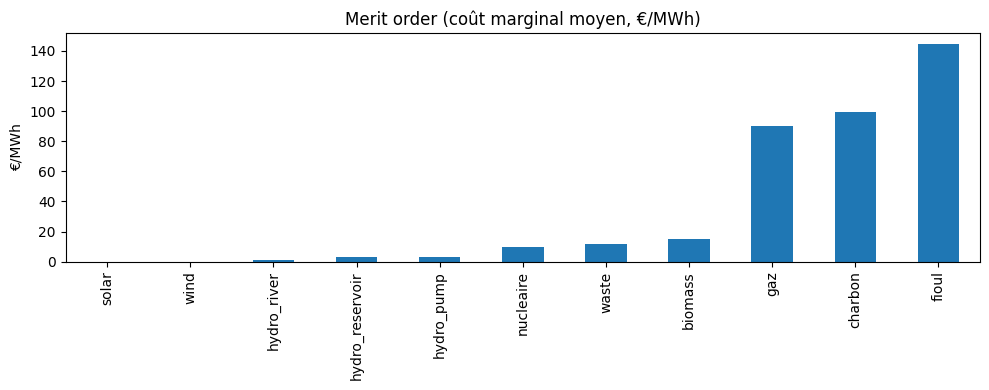

In [9]:
couts_marginaux_moyens = {
    "solar": 0, "wind": 0, "nucleaire": p_utilises["cout_marginal_nucleaire"],
    "gaz": (df_donnees["TTF"] / p_utilises["rendement_gaz"] + df_donnees["EUA"] * p_utilises["emission_gaz"] / p_utilises["rendement_gaz"]).mean(),
    "charbon": p_utilises["prix_charbon_hyp"] / p_utilises["rendement_charbon"] + df_donnees["EUA"].mean() * p_utilises["emission_charbon"] / p_utilises["rendement_charbon"],
    "fioul": p_utilises["prix_fioul_hyp"] / p_utilises["rendement_fioul"] + df_donnees["EUA"].mean() * p_utilises["emission_fioul"] / p_utilises["rendement_fioul"],
    "biomass": 15, "waste": 12, "hydro_river": p_utilises["cout_marginal_hydro_fil_eau"], "hydro_reservoir": p_utilises["cout_marginal_barrage"], "hydro_pump": p_utilises["cout_marginal_step"],
}
merit_order = pd.Series(couts_marginaux_moyens).sort_values()
merit_order.plot.bar(figsize=(10, 4), title="Merit order (coût marginal moyen, €/MWh)")
plt.ylabel("€/MWh"); plt.tight_layout(); plt.show()

**Distribution du coût marginal du gaz en fonction du temps (varie en fonction du prix du carbone et du gaz)**

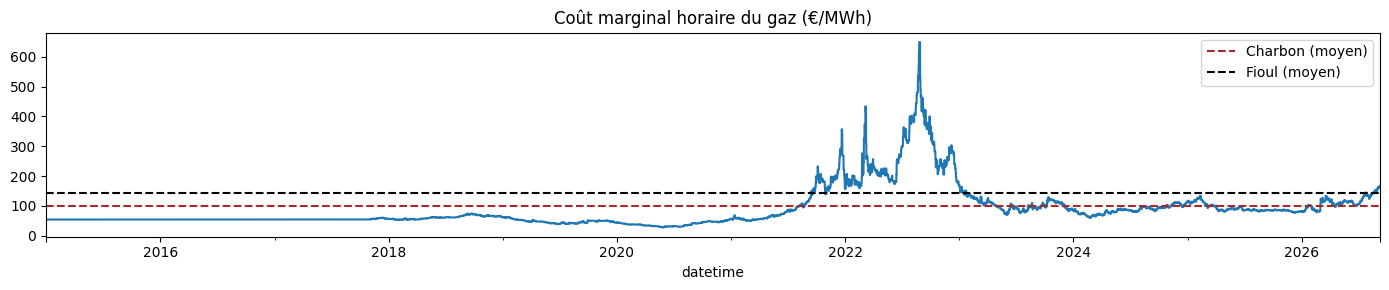

In [10]:
cout_gaz_horaire = df_donnees["TTF"] / p_utilises["rendement_gaz"] + df_donnees["EUA"] * p_utilises["emission_gaz"] / p_utilises["rendement_gaz"]
cout_gaz_horaire.plot(figsize=(14, 3), title="Coût marginal horaire du gaz (€/MWh)")
plt.axhline(couts_marginaux_moyens["charbon"], color="brown", linestyle="--", label="Charbon (moyen)")
plt.axhline(couts_marginaux_moyens["fioul"], color="black", linestyle="--", label="Fioul (moyen)")
plt.legend(); plt.tight_layout(); plt.show()

**Energie par fiière**

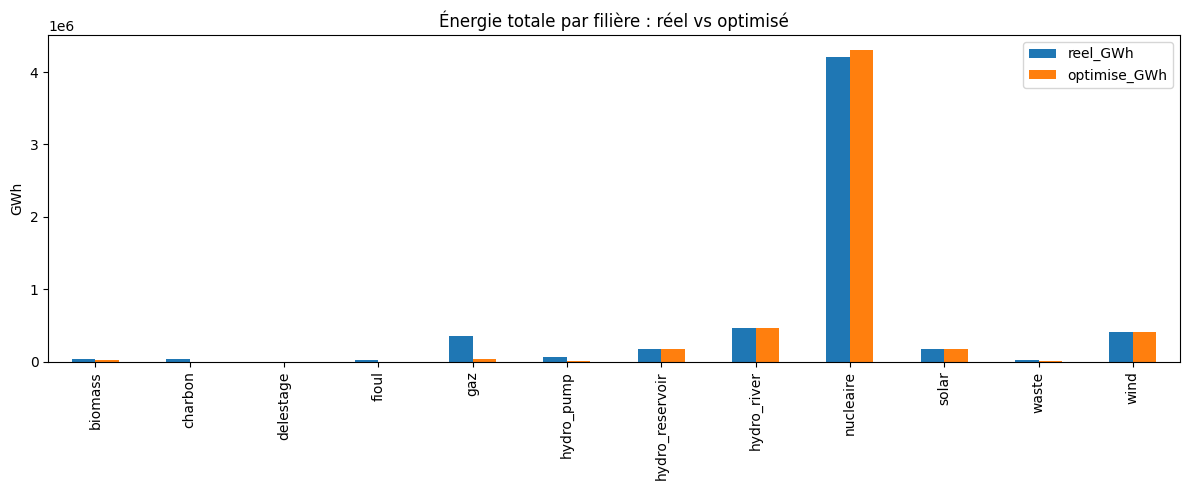

In [11]:
comparaison_annuelle_totale[["reel_GWh", "optimise_GWh"]].plot.bar(figsize=(12, 5))
plt.title("Énergie totale par filière : réel vs optimisé"); plt.ylabel("GWh")
plt.tight_layout(); plt.show()

**Série temporelle par filière**

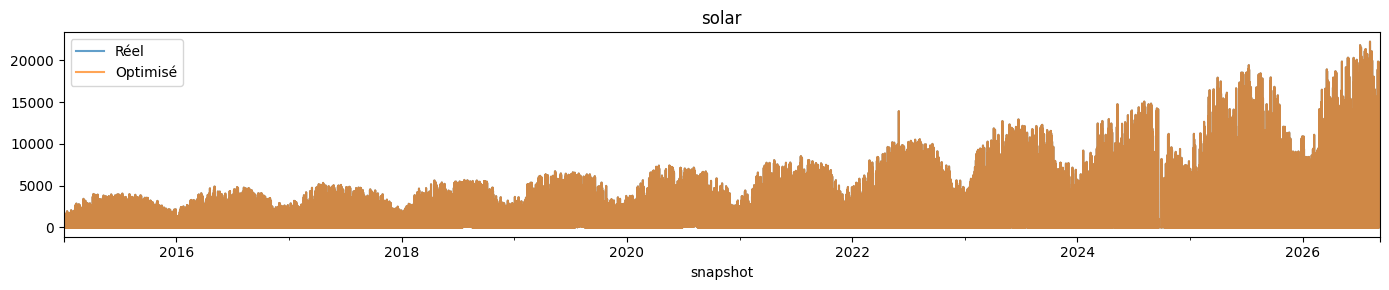

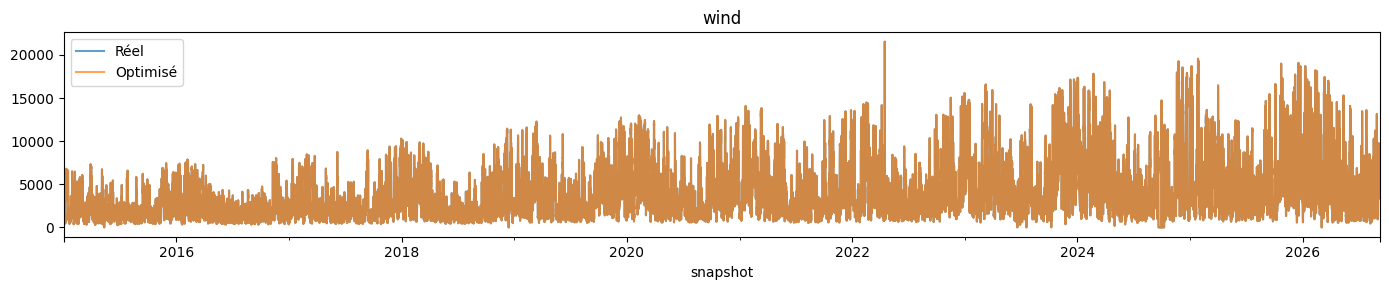

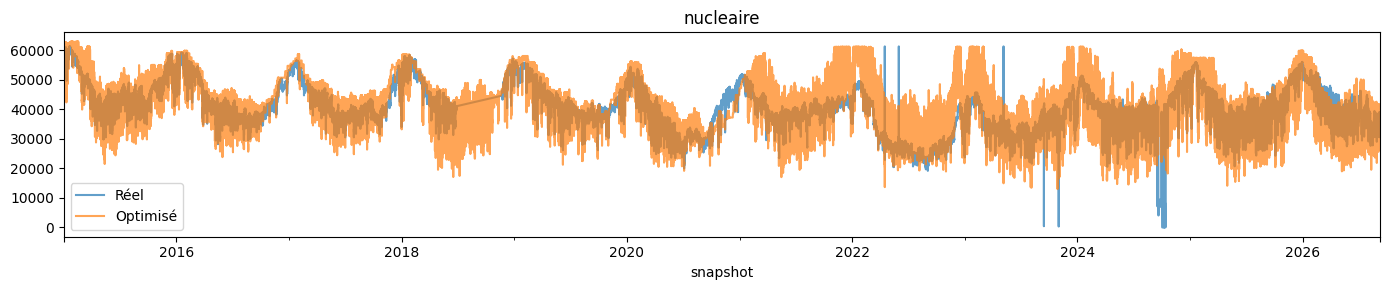

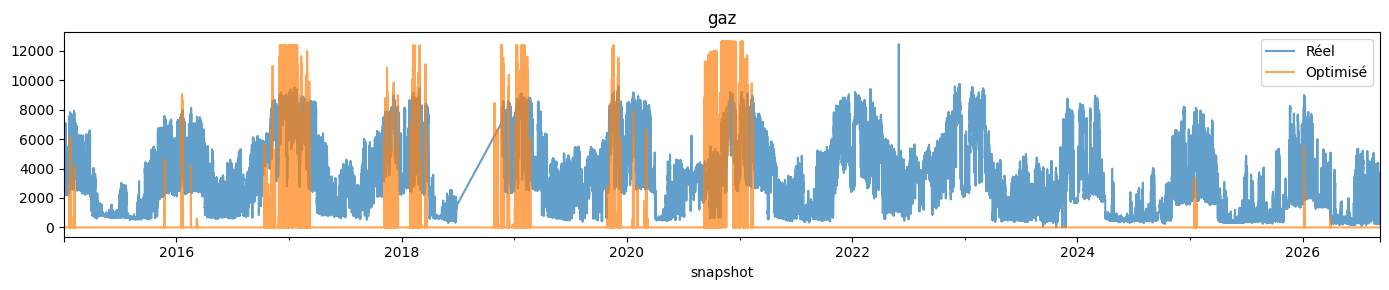

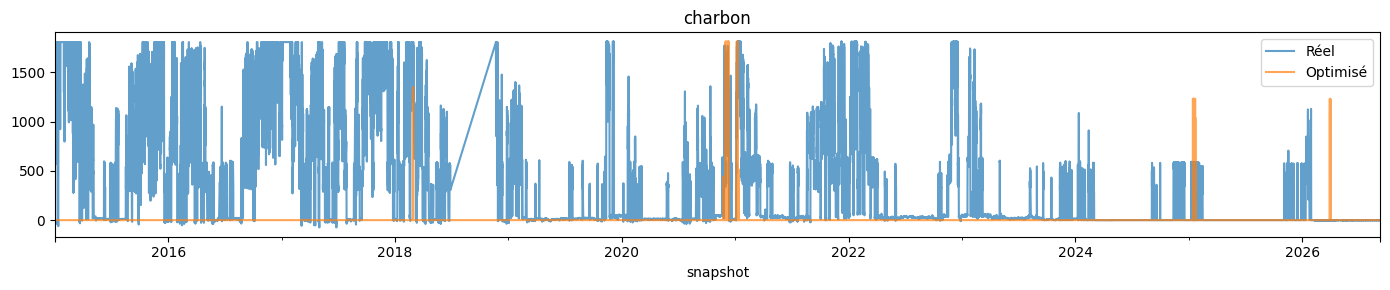

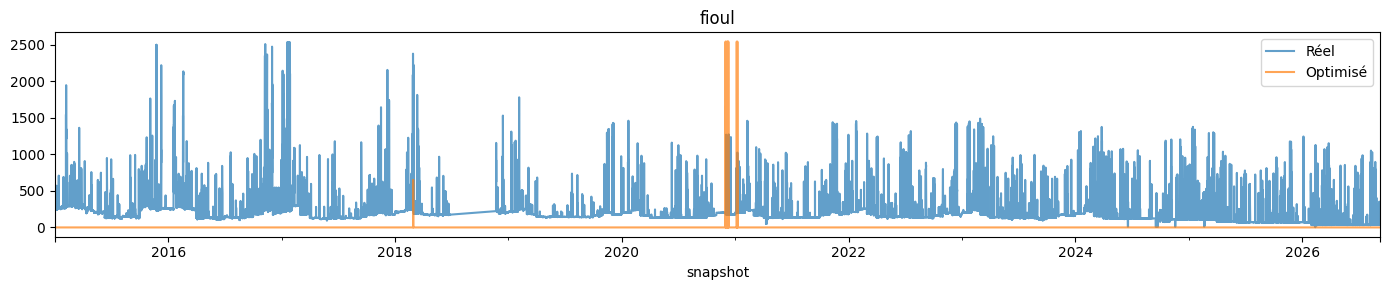

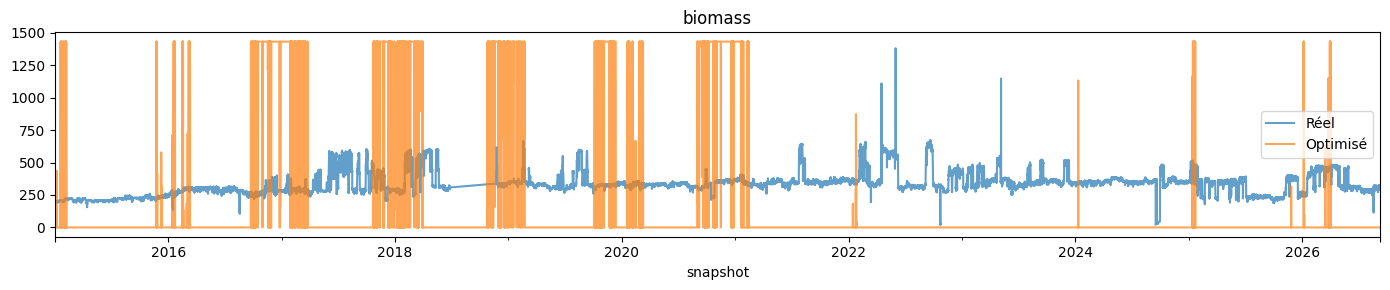

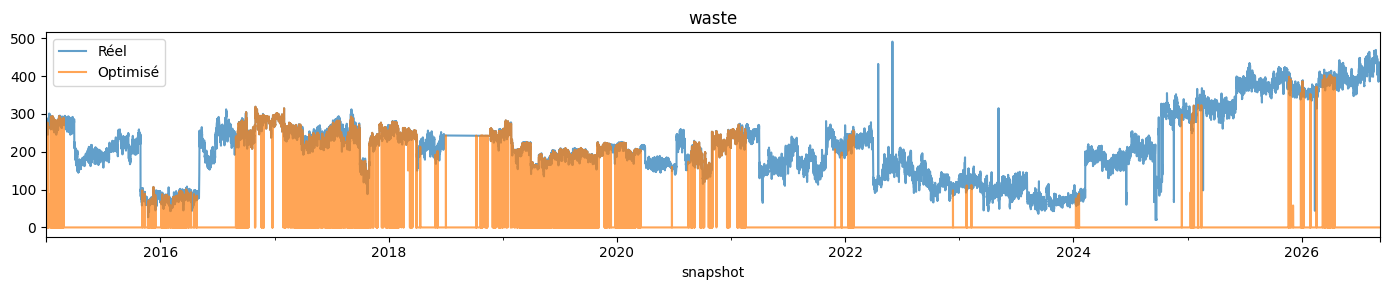

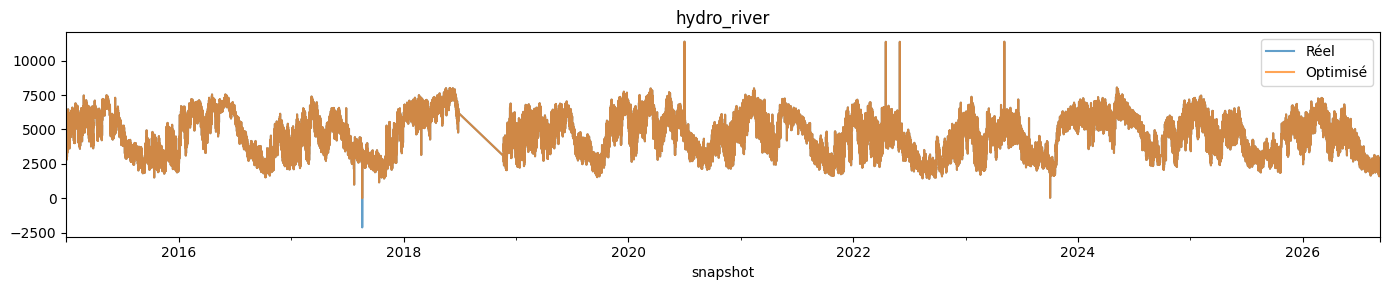

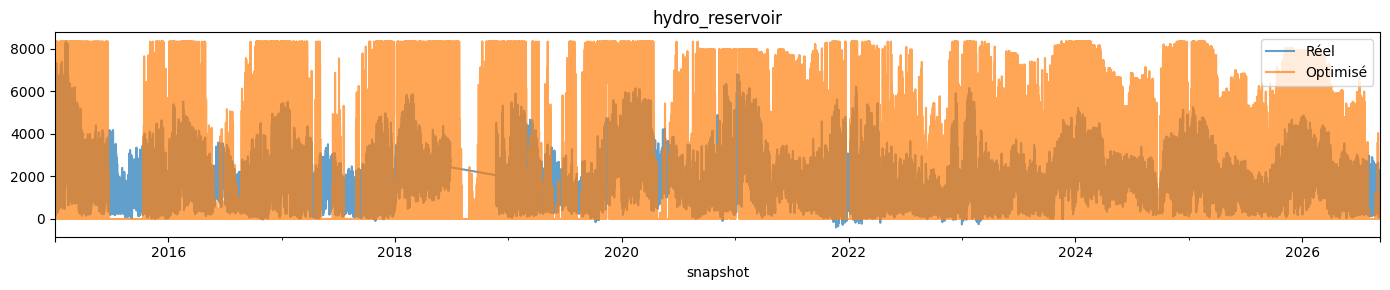

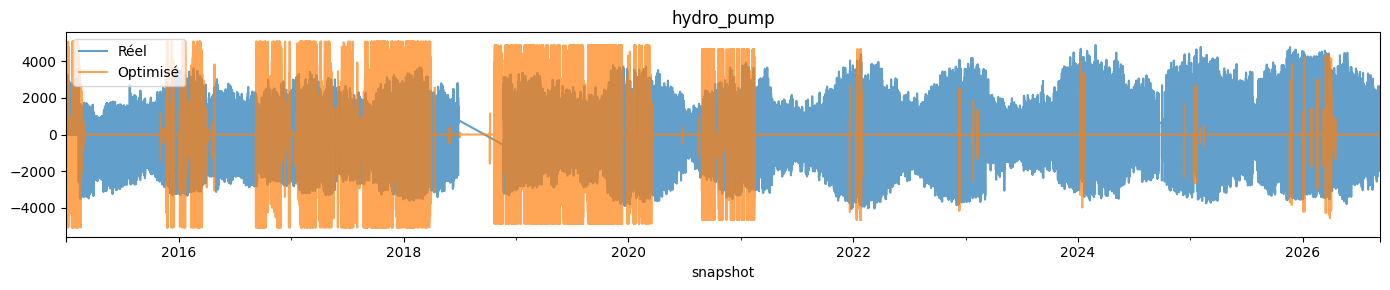

In [12]:
comparaison = pd.DataFrame({f"{g}_optimise": n.generators_t.p[g] for g in
                             ["solar", "wind", "nucleaire", "gaz", "charbon", "fioul", "biomass", "waste", "hydro_river"]})
for g, c in mapping.items():
    if g in comparaison.columns.str.replace("_optimise", "").values or f"{g}_optimise" in comparaison.columns:
        comparaison[f"{g}_reel"] = df_donnees[c]
comparaison["hydro_reservoir_optimise"] = n.storage_units_t.p["hydro_reservoir"]
comparaison["hydro_reservoir_reel"] = df_donnees["prod_hydro_reservoir_mw"]
comparaison["hydro_pump_optimise"] = n.storage_units_t.p["hydro_pump"]
comparaison["hydro_pump_reel"] = df_donnees["prod_hydro_pump_mw"]

for g in ["solar", "wind", "nucleaire", "gaz", "charbon", "fioul", "biomass", "waste",
          "hydro_river", "hydro_reservoir", "hydro_pump"]:
    fig, ax = plt.subplots(figsize=(14, 3))
    comparaison[f"{g}_reel"].plot(ax=ax, label="Réel", alpha=0.7)
    comparaison[f"{g}_optimise"].plot(ax=ax, label="Optimisé", alpha=0.7)
    ax.set_title(g); ax.legend(); plt.tight_layout(); plt.show()

**Comportement des stockages en fonction du temps**

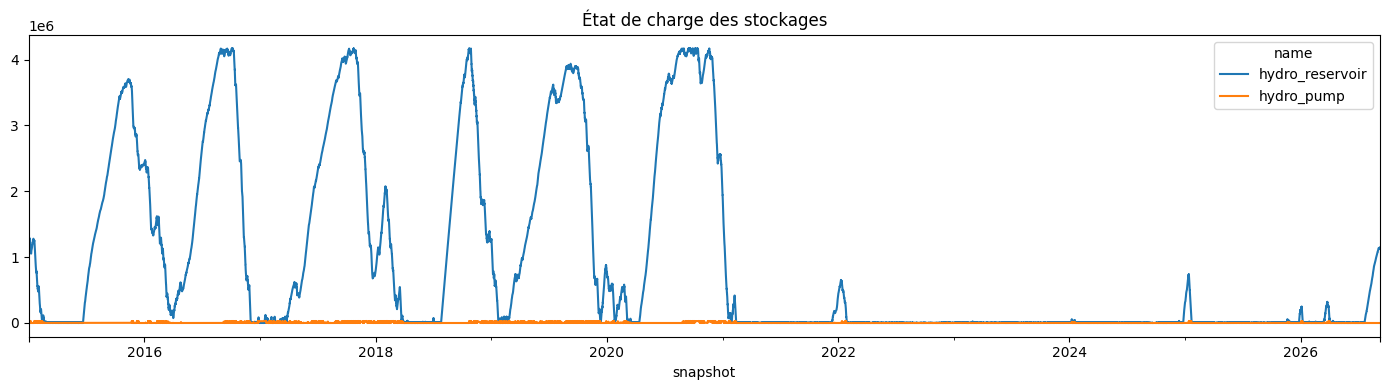

In [13]:
n.storage_units_t.state_of_charge.plot(figsize=(14, 4), title="État de charge des stockages")
plt.tight_layout(); plt.show()

**Durée classée par filière**

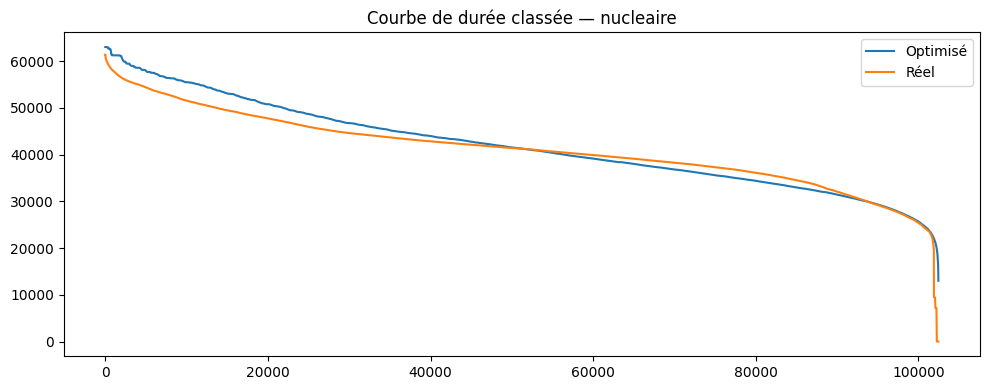

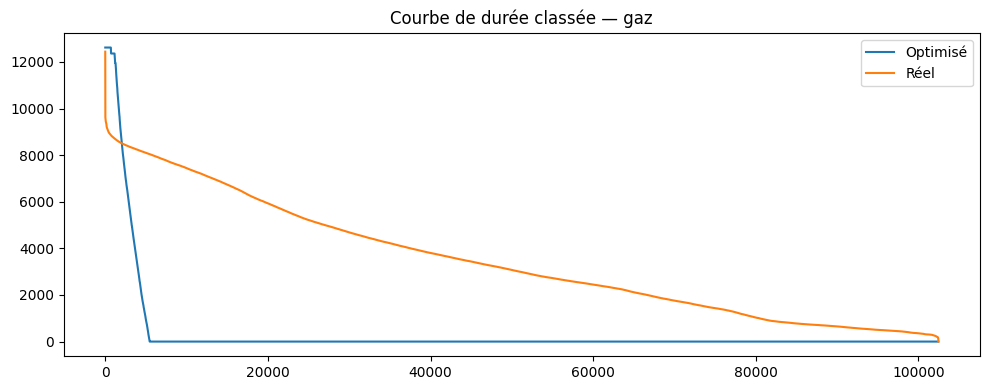

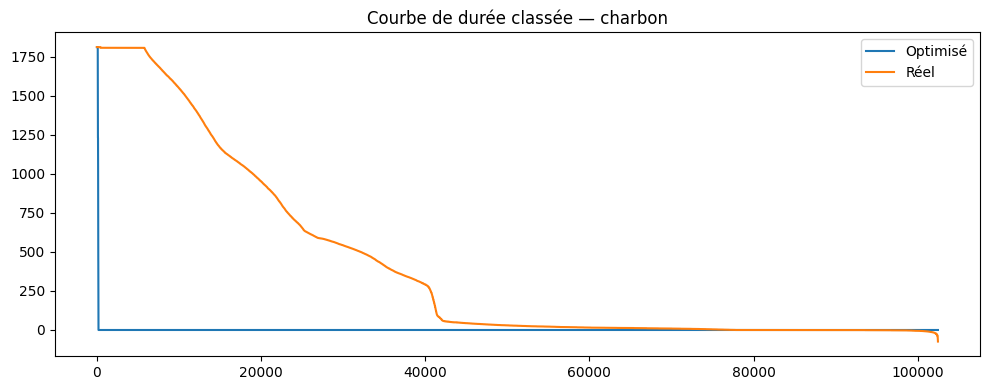

In [14]:
for g in ["nucleaire", "gaz", "charbon"]:
    fig, ax = plt.subplots(figsize=(10, 4))
    n.generators_t.p[g].sort_values(ascending=False).reset_index(drop=True).plot(ax=ax, label="Optimisé")
    df_donnees[mapping[g]].sort_values(ascending=False).reset_index(drop=True).plot(ax=ax, label="Réel")
    ax.set_title(f"Courbe de durée classée — {g}"); ax.legend(); plt.tight_layout(); plt.show()

**Visualisation des flux énergétiques au cours du temps**

<Axes: title={'center': 'Énergie totale par filière (GWh)'}, ylabel='carrier'>

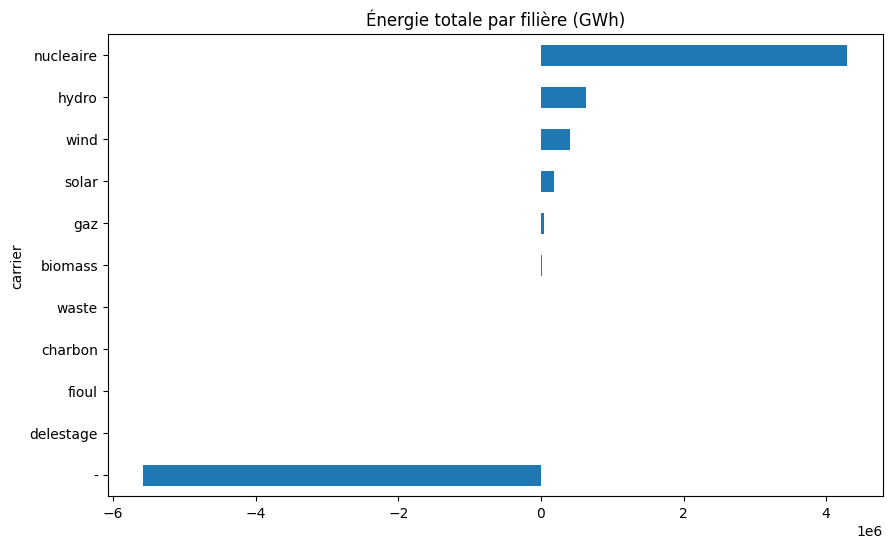

In [15]:
balance = n.statistics.energy_balance()
balance.groupby(level="carrier").sum().div(1000).sort_values().plot.barh(figsize=(10,6), title="Énergie totale par filière (GWh)")

In [ ]:
n.sanitize()

#Les plots sur les différentes énergies mobilisées
n.statistics.energy_balance.plot()
n.statistics.energy_balance.iplot.area()

INFO:pypsa.consistency:Sanitizing network...
INFO:pypsa.components._types.carriers:Adding 11 missing carriers: ['AC', 'biomass', 'charbon', 'delestage', 'fioul', 'gaz', 'hydro', 'nucleaire', 'solar', 'waste', 'wind']
INFO:pypsa.components._types.carriers:Assigned colors to 11 carriers using 'tab10' palette.
INFO:pypsa.consistency:Network sanitization complete.


# **Analayse de sensibilité**

In [ ]:
def etude_sensibilite(grille_parametres, solver_name="highs"):
    """grille_parametres : dict {nom_param: [valeur1, valeur2, valeur3]}.
    Fait varier UN paramètre à la fois (les autres restent aux valeurs
    par défaut), résout à chaque fois, et retourne un dict de DataFrames
    {nom_param: DataFrame(carrier x valeur -> énergie totale GWh)}."""
    resultats = {}

    for nom_param, valeurs in grille_parametres.items():
        print(f"\n=== Sensibilité : {nom_param} ===")
        mix_par_valeur = {}

        for v in valeurs:
            n_test = build_and_solve_network(overrides={nom_param: v}, solver_name=solver_name)
            energie_par_carrier = n_test.statistics.energy_balance()
            energie_par_carrier = energie_par_carrier.groupby(level="carrier").sum() / 1000  # GWh
            mix_par_valeur[v] = energie_par_carrier

        df_resultat = pd.DataFrame(mix_par_valeur).round(0)
        print(df_resultat)
        resultats[nom_param] = df_resultat

    return resultats


# Grille resserrée sur les paramètres les moins bien sourcés / les plus
# incertains — le plan complet (8 paramètres) est possible si le temps
# le permet, mais chaque run recalcule tout le LP (~102 457 pas de temps).
grille_prioritaire = {
    "cout_marginal_nucleaire": [5, 10, 12],
    "prix_charbon_hyp": [10, 15, 25],   # le moins sourcé de tous les paramètres
    "prix_fioul_hyp": [30, 40, 60],     # idem
}

resultats_sensibilite = etude_sensibilite(grille_prioritaire)

# Grille complète (optionnelle) :
grille_complete = {
    **grille_prioritaire,
    "rendement_charbon": [0.35, 0.375, 0.40],
    "rendement_fioul": [0.35, 0.375, 0.40],
    "emission_charbon": [0.34, 0.35, 0.36],
    "emission_fioul": [0.265, 0.275, 0.285],
    "cout_marginal_barrage": [1, 3, 5],
    "cout_marginal_step": [1, 3, 5],
}
# resultats_sensibilite_complet = etude_sensibilite(grille_complete)


=== Sensibilité : cout_marginal_nucleaire ===


C:\Users\arthu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pypsa\network\io.py:2082: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objecti

                  5          10         12
carrier                                   
-         -5584263.0 -5584263.0 -5584263.0
biomass      19855.0    19889.0    19889.0
charbon        263.0      263.0      263.0
delestage       25.0       25.0       25.0
fioul          120.0      120.0      120.0
gaz          36953.0    36953.0    36953.0
hydro       637333.0   637507.0   637507.0
nucleaire  4299703.0  4298835.0  4298835.0
solar       180613.0   180613.0   180613.0
waste         3782.0     4442.0     4442.0
wind        405615.0   405615.0   405615.0

=== Sensibilité : prix_charbon_hyp ===


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 14.18it/s]
INFO:linopy.io: Writing time: 3.99s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

                  10         15         25
carrier                                   
-         -5584263.0 -5584263.0 -5584263.0
biomass      19889.0    19889.0    19889.0
charbon        263.0      263.0      208.0
delestage       25.0       25.0       25.0
fioul          120.0      120.0      131.0
gaz          36953.0    36953.0    36996.0
hydro       637507.0   637507.0   637509.0
nucleaire  4298835.0  4298835.0  4298835.0
solar       180613.0   180613.0   180613.0
waste         4442.0     4442.0     4442.0
wind        405615.0   405615.0   405615.0

=== Sensibilité : prix_fioul_hyp ===


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 13.19it/s]
INFO:linopy.io: Writing time: 4.05s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

                  30         40         60
carrier                                   
-         -5584263.0 -5584263.0 -5584263.0
biomass      19889.0    19889.0    19889.0
charbon        250.0      263.0      263.0
delestage       25.0       25.0       25.0
fioul          131.0      120.0      120.0
gaz          36953.0    36953.0    36953.0
hydro       637509.0   637507.0   637507.0
nucleaire  4298835.0  4298835.0  4298835.0
solar       180613.0   180613.0   180613.0
waste         4442.0     4442.0     4442.0
wind        405615.0   405615.0   405615.0


# **Scénario avec contraintes sur prix du gaz et du carbone**

Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 43.81it/s]
INFO:linopy.io: Writing time: 1.41s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

EUA x1.0 (moyenne 65 €/t) — délestage: 25.4 GWh


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 25.64it/s]
INFO:linopy.io: Writing time: 1.86s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

EUA x1.5 (moyenne 98 €/t) — délestage: 25.4 GWh


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 22.84it/s]
INFO:linopy.io: Writing time: 2.01s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

EUA x2.0 (moyenne 130 €/t) — délestage: 25.4 GWh


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 22.76it/s]
INFO:linopy.io: Writing time: 2.17s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

EUA x3.0 (moyenne 195 €/t) — délestage: 25.4 GWh


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 25.88it/s]
INFO:linopy.io: Writing time: 2.05s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

EUA x5.0 (moyenne 326 €/t) — délestage: 25.4 GWh
                 1.0        1.5        2.0        3.0        5.0
carrier                                                         
-         -5584263.0 -5584263.0 -5584263.0 -5584263.0 -5584263.0
biomass      19889.0    19889.0    19889.0    19889.0    19889.0
charbon        263.0      221.0      208.0      208.0       81.0
delestage       25.0       25.0       25.0       25.0       25.0
fioul          120.0      120.0      131.0      131.0      258.0
gaz          36953.0    36996.0    36995.0    36995.0    36995.0
hydro       637507.0   637507.0   637510.0   637510.0   637510.0
nucleaire  4298835.0  4298835.0  4298835.0  4298835.0  4298835.0
solar       180613.0   180613.0   180613.0   180613.0   180613.0
waste         4442.0     4442.0     4442.0     4442.0     4442.0
wind        405615.0   405615.0   405615.0   405615.0   405615.0


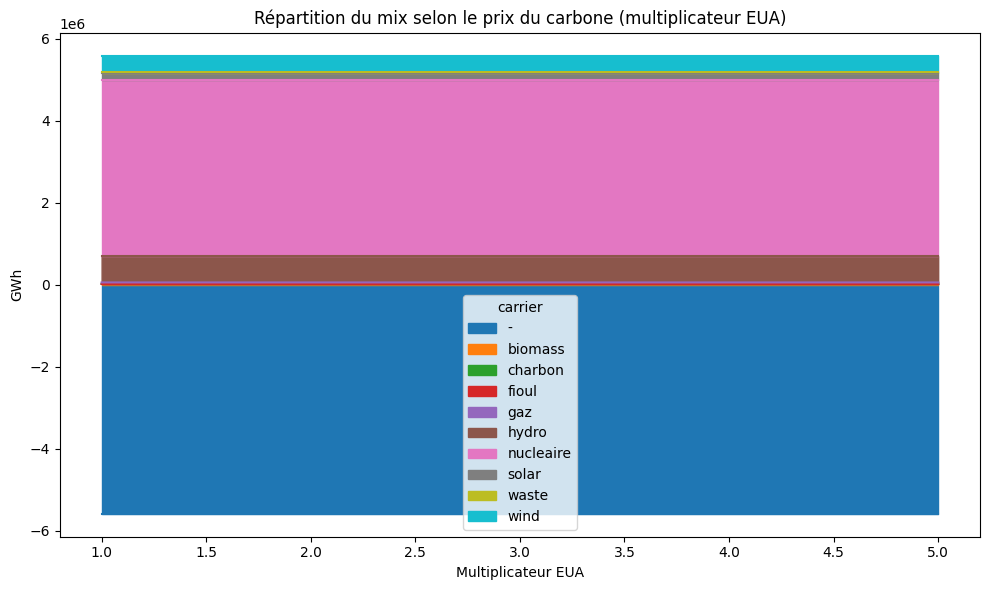

In [ ]:
def scenario_prix_carbone(multiplicateurs_eua, solver_name="highs"):
    resultats = {}
    for mult in multiplicateurs_eua:
        overrides = {}  # le multiplicateur s'applique directement au calcul du marginal_cost gaz/charbon/fioul
        n_test = build_and_solve_network(solver_name=solver_name)
        # On ne peut pas passer le multiplicateur via overrides (il agit sur df_donnees["EUA"],
        # pas sur un scalaire de PARAMS_DEFAUT) -> on reconstruit le réseau avec un DataFrame modifié
        # Solution la plus propre : dupliquer temporairement la colonne EUA avec le multiplicateur
        global df_donnees
        eua_original = df_donnees["EUA"].copy()
        df_donnees["EUA"] = eua_original * mult
        n_test = build_and_solve_network(solver_name=solver_name)
        df_donnees["EUA"] = eua_original  # restauration immédiate, indispensable

        mix = n_test.statistics.energy_balance().groupby(level="carrier").sum() / 1000
        resultats[mult] = mix
        print(f"EUA x{mult} (moyenne {eua_original.mean()*mult:.0f} €/t) — délestage: {mix.get('delestage', 0):.1f} GWh")

    df_resultat = pd.DataFrame(resultats).round(0)
    print(df_resultat)
    return df_resultat

resultats_prix_carbone = scenario_prix_carbone([1.0, 1.5, 2.0, 3.0, 5.0])

# Visualisation : part de chaque filière selon le multiplicateur EUA
resultats_prix_carbone.T.drop(columns=["delestage"], errors="ignore").plot.area(figsize=(10,6), stacked=True)
plt.title("Répartition du mix selon le prix du carbone (multiplicateur EUA)")
plt.xlabel("Multiplicateur EUA"); plt.ylabel("GWh")
plt.tight_layout(); plt.show()

Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 31.61it/s]
INFO:linopy.io: Writing time: 1.97s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 100% du réel — prix carbone implicite : 0.0 €/tCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 29.05it/s]
INFO:linopy.io: Writing time: 2.75s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 75% du réel — prix carbone implicite : 0.0 €/tCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 24.24it/s]
INFO:linopy.io: Writing time: 3.59s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 50% du réel — prix carbone implicite : 0.0 €/tCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 24.73it/s]
INFO:linopy.io: Writing time: 2.53s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 25% du réel — prix carbone implicite : 0.0 €/tCO2
                1.00       0.75       0.50       0.25
carrier                                              
-         -5584263.0 -5584263.0 -5584263.0 -5584263.0
biomass      19889.0    19889.0    19889.0    19889.0
charbon        263.0      263.0      263.0      263.0
delestage       25.0       25.0       25.0       25.0
fioul          120.0      120.0      120.0      120.0
gaz          36953.0    36953.0    36953.0    36953.0
hydro       637507.0   637507.0   637507.0   637507.0
nucleaire  4298835.0  4298835.0  4298835.0  4298835.0
solar       180613.0   180613.0   180613.0   180613.0
waste         4442.0     4442.0     4442.0     4442.0
wind        405615.0   405615.0   405615.0   405615.0


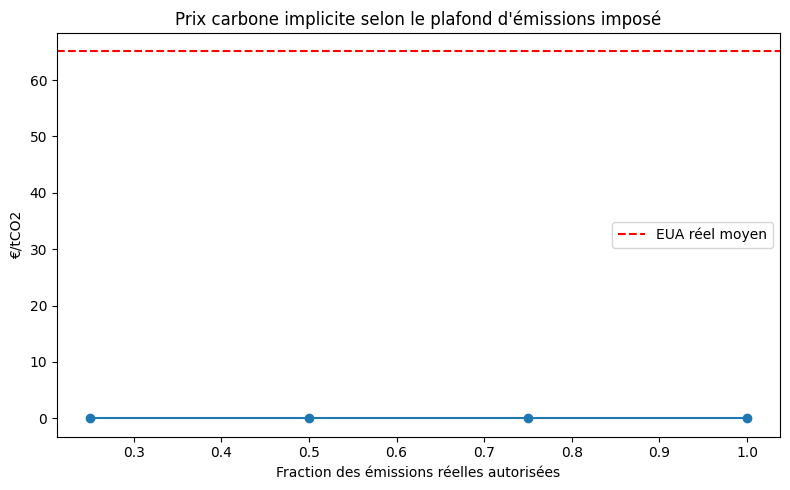

In [ ]:
emissions_reelles = (
    (df_donnees["prod_gas_mw"] * PARAMS_DEFAUT["emission_gaz"] / PARAMS_DEFAUT["rendement_gaz"]).sum()
    + (df_donnees["prod_coal_mw"] * PARAMS_DEFAUT["emission_charbon"] / PARAMS_DEFAUT["rendement_charbon"]).sum()
    + (df_donnees["prod_oil_mw"] * PARAMS_DEFAUT["emission_fioul"] / PARAMS_DEFAUT["rendement_fioul"]).sum()
) / 1000  # ktCO2 (à adapter selon l'unité de tes MWh)

def scenario_plafond_co2(fractions_du_reel, solver_name="highs"):
    resultats = {}
    prix_implicites = {}
    for frac in fractions_du_reel:
        plafond = emissions_reelles * frac
        n_test = build_and_solve_network(co2_cap=plafond, solver_name=solver_name)
        mix = n_test.statistics.energy_balance().groupby(level="carrier").sum() / 1000
        resultats[frac] = mix
        prix_implicites[frac] = n_test.global_constraints.at["co2_limit", "mu"]
        print(f"Plafond {frac*100:.0f}% du réel — prix carbone implicite : {prix_implicites[frac]:.1f} €/tCO2")

    df_resultat = pd.DataFrame(resultats).round(0)
    print(df_resultat)
    return df_resultat, prix_implicites

resultats_plafond, prix_implicites = scenario_plafond_co2([1.0, 0.75, 0.5, 0.25])

pd.Series(prix_implicites).plot(marker="o", figsize=(8,5),
    title="Prix carbone implicite selon le plafond d'émissions imposé")
plt.axhline(df_donnees["EUA"].mean(), color="red", linestyle="--", label="EUA réel moyen")
plt.xlabel("Fraction des émissions réelles autorisées"); plt.ylabel("€/tCO2"); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
def emissions_generateur(n_ref, gen, emission_factor, rendement):
    return (n_ref.generators_t.p[gen] / rendement * emission_factor).sum() / 1000  # ktCO2

n_base = build_and_solve_network()  # ton run de référence, sans contrainte
emissions_base_optimisee = (
    emissions_generateur(n_base, "gaz", PARAMS_DEFAUT["emission_gaz"], PARAMS_DEFAUT["rendement_gaz"])
    + emissions_generateur(n_base, "charbon", PARAMS_DEFAUT["emission_charbon"], PARAMS_DEFAUT["rendement_charbon"])
    + emissions_generateur(n_base, "fioul", PARAMS_DEFAUT["emission_fioul"], PARAMS_DEFAUT["rendement_fioul"])
)
print(f"Émissions du dispatch optimisé de référence : {emissions_base_optimisee:.0f} ktCO2")

# Il faut descendre BIEN en dessous de ce chiffre pour que la contrainte morde
resultats_plafond, prix_implicites = scenario_plafond_co2(
    [1.0, 0.5, 0.25, 0.1, 0.05], solver_name="highs"  # fractions du baseline OPTIMISÉ, pas du réel
)

Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 40.23it/s]
INFO:linopy.io: Writing time: 1.91s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

Émissions du dispatch optimisé de référence : 13897 ktCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00,  9.31it/s]
INFO:linopy.io: Writing time: 3.98s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 100% du réel — prix carbone implicite : 0.0 €/tCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 24.39it/s]
INFO:linopy.io: Writing time: 2.94s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 50% du réel — prix carbone implicite : 0.0 €/tCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 16.51it/s]
INFO:linopy.io: Writing time: 2.25s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 25% du réel — prix carbone implicite : 0.0 €/tCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 17.53it/s]
INFO:linopy.io: Writing time: 3.32s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1844226 primals, 358599

Plafond 10% du réel — prix carbone implicite : 0.0 €/tCO2


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'biomass',
       'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 28.11it/s]
INFO:linopy.io: Writing time: 1.86s


# **Scénario sur indisponibilité massive du nucléaire**

Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 19.68it/s]
INFO:linopy.io: Writing time: 2.96s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

Facteur x1.0 — nucléaire: 4298835 GWh, gaz: 36953 GWh, délestage: 25.4 GWh


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 21.89it/s]
INFO:linopy.io: Writing time: 2.33s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

Facteur x1.5 — nucléaire: 4045132 GWh, gaz: 227275 GWh, délestage: 7842.5 GWh


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 24.33it/s]
INFO:linopy.io: Writing time: 2.93s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

Facteur x2.0 — nucléaire: 3639976 GWh, gaz: 484216 GWh, délestage: 87446.8 GWh


Index(['reseau'], dtype='object', name='name')
Index(['solar', 'wind', 'hydro_river', 'waste', 'nucleaire', 'gaz', 'charbon',
       'fioul', 'biomass', 'delestage'],
      dtype='object', name='name')
Index(['hydro_reservoir', 'hydro_pump'], dtype='object', name='name')
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:81: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 17.61it/s]
INFO:linopy.io: Writing time: 5.08s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Soluti

Facteur x3.0 — nucléaire: 2847766 GWh, gaz: 655185 GWh, délestage: 600849.8 GWh
                 1.0        1.5        2.0        3.0
carrier                                              
-         -5584263.0 -5584263.0 -5584263.0 -5584263.0
biomass      19889.0    59283.0    77615.0    86969.0
charbon        263.0     5465.0    30139.0    63127.0
delestage       25.0     7843.0    87447.0   600850.0
fioul          120.0     6774.0    29921.0    91403.0
gaz          36953.0   227275.0   484216.0   655185.0
hydro       637507.0   636071.0   635381.0   637517.0
nucleaire  4298835.0  4045132.0  3639976.0  2847766.0
solar       180613.0   180613.0   180613.0   180613.0
waste         4442.0    10192.0    13339.0    15219.0
wind        405615.0   405615.0   405615.0   405615.0


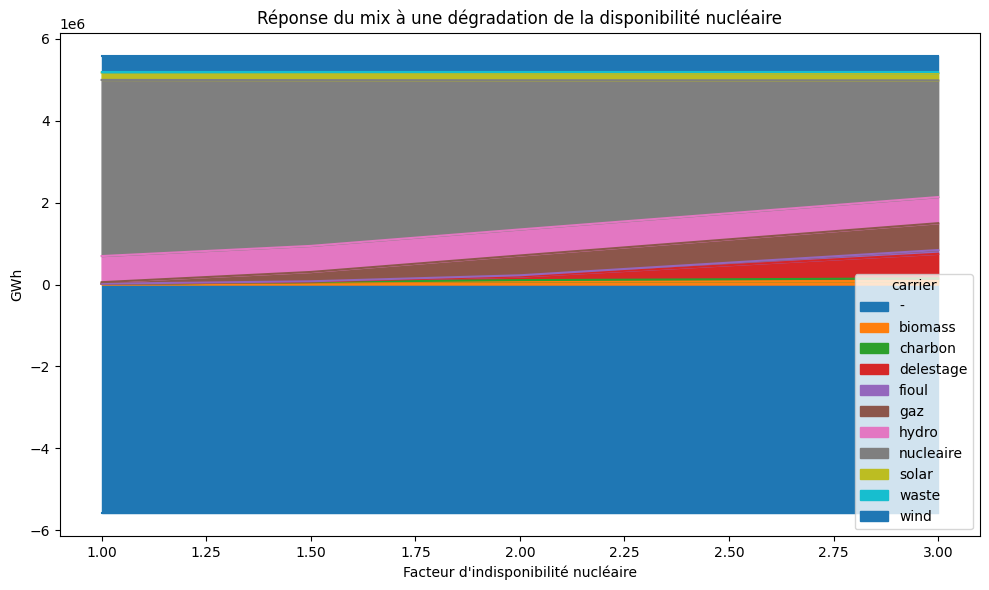

In [ ]:
def scenario_crise_nucleaire(facteurs, solver_name="highs"):
    resultats = {}
    for f in facteurs:
        n_test = build_and_solve_network(facteur_indispo_nucleaire=f, solver_name=solver_name)
        mix = n_test.statistics.energy_balance().groupby(level="carrier").sum() / 1000
        resultats[f] = mix
        delestage = mix.get("delestage", 0)
        print(f"Facteur x{f} — nucléaire: {mix['nucleaire']:.0f} GWh, "
              f"gaz: {mix.get('gaz', 0):.0f} GWh, délestage: {delestage:.1f} GWh")

    df_resultat = pd.DataFrame(resultats).round(0)
    print(df_resultat)
    return df_resultat

resultats_crise_nuc = scenario_crise_nucleaire([1.0, 1.5, 2.0, 3.0])

resultats_crise_nuc.T.drop(index=[], errors="ignore").plot.area(figsize=(10,6), stacked=True)
plt.title("Réponse du mix à une dégradation de la disponibilité nucléaire")
plt.xlabel("Facteur d'indisponibilité nucléaire"); plt.ylabel("GWh")
plt.tight_layout(); plt.show()